In [1]:
running_on_colab = False
if running_on_colab:
    from google.colab import drive

    drive.mount("/content/drive")

import json
import os
import pickle
import random
import re
import shutil
import warnings
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

# Google Drive folders
DATA_DIR = Path("/content/drive/MyDrive/DATA" if running_on_colab else ("./DATA/DATA"))
OUT_DIR = (DATA_DIR / "combined_run") if running_on_colab else Path("./output")
PROC_DIR = OUT_DIR / "processed"
MODEL_DIR = OUT_DIR / "models"
FIG_DIR = OUT_DIR / "figures"

for folder in [OUT_DIR, PROC_DIR, MODEL_DIR, FIG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Assignment parameters
TARGETS = ["p (mbar)", "T (degC)", "rh (%)", "wv (m/s)"]
TIME_FEATURES = ["hour_sin", "hour_cos", "doy_sin", "doy_cos"]
ALL_FEATURES = TARGETS + TIME_FEATURES
N_TARGETS = len(TARGETS)
N_FEATURES = len(ALL_FEATURES)

K = 6
TRAIN_FRAC = 0.70
VAL_FRAC = 0.15

BATCH_SIZE = 64
LEARNING_RATE = 0.001
MAX_EPOCHS = 50
PATIENCE = 7
HORIZON = 6

# Find ZIP files
zip_paths = sorted(DATA_DIR.glob("mpi_saale_*.zip"))

print(DATA_DIR)
if not zip_paths:
    raise FileNotFoundError("No ZIP files found")

print("ZIP files found:", len(zip_paths))


def normalize_col(c):
    return re.sub(r"\s+", " ", str(c).strip())


frames = []
inventory = []

# Read all CSV/TXT files inside ZIP files
for zp in zip_paths:
    with zipfile.ZipFile(zp, "r") as zf:
        members = [x for x in zf.namelist() if x.lower().endswith((".csv", ".txt"))]

        for member in members:
            try:
                with zf.open(member) as f:
                    df = pd.read_csv(f, sep=";", low_memory=False)

                    if df.shape[1] <= 1:
                        f.seek(0)
                        df = pd.read_csv(f, sep=",", low_memory=False)

                df.columns = [normalize_col(c) for c in df.columns]

                frames.append(df)

                inventory.append({"ZIP": zp.name, "File": member, "Rows": len(df)})

            except Exception as e:
                print("File reading error:", member, e)

if not frames:
    raise RuntimeError("No CSV data could be read.")

raw = pd.concat(frames, ignore_index=True, sort=False)

print("\nRaw rows:", len(raw))
print("Available columns:")
print(list(raw.columns))

pd.DataFrame(inventory).to_csv(PROC_DIR / "input_file_inventory.csv", index=False)

Device: cpu
DATA/DATA
ZIP files found: 16

Raw rows: 419515
Available columns:
['Date Time', 'p (mbar)', 'T (degC)', 'rh (%)', 'sh (g/kg)', 'Tpot (K)', 'Tdew (degC)', 'VPmax (mbar)', 'VPact (mbar)', 'VPdef (mbar)', 'H2OC (mmol/mol)', 'rho (g/m**3)', 'wv (m/s)', 'wd (deg)', 'rain (mm)', 'SWDR (W/m**2)', 'SDUR (s)', 'TRAD (degC)', 'Rn (W/m**2)', 'ST002 (degC)', 'ST004 (degC)', 'ST008 (degC)', 'ST016 (degC)', 'ST032 (degC)', 'ST064 (degC)', 'ST128 (degC)', 'SM008 (%)', 'SM016 (%)', 'SM032 (%)', 'SM064 (%)', 'SM128 (%)']


In [2]:
def find_column(columns, candidates):

    lookup = {str(c).strip().lower(): c for c in columns}

    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]

    return None


# Identify timestamp column
date_col = find_column(
    raw.columns, ["Date Time", "datetime", "date_time", "timestamp", "date"]
)

if date_col is None:
    raise KeyError("Timestamp column not identified. Check the column names.")

# Identify weather columns
column_aliases = {
    "p (mbar)": ["p (mbar)", "p", "pressure"],
    "T (degC)": ["T (degC)", "T", "temperature"],
    "rh (%)": ["rh (%)", "rh", "relative humidity"],
    "wv (m/s)": ["wv (m/s)", "wv", "wind velocity", "wind speed"],
}

rename_map = {}

for target, aliases in column_aliases.items():
    found = find_column(raw.columns, aliases)

    if found is None:
        raise KeyError(f"Missing {target}. Available columns: {list(raw.columns)}")

    rename_map[found] = target


data = (
    raw[[date_col] + list(rename_map.keys())]
    .rename(columns={date_col: "Date Time", **rename_map})
    .copy()
)

# Parse date and time
data["Date Time"] = pd.to_datetime(data["Date Time"], errors="coerce", dayfirst=True)

invalid_dates = int(data["Date Time"].isna().sum())

data = data.dropna(subset=["Date Time"]).copy()

# Convert measurements to numerical values
for col in TARGETS:
    data[col] = pd.to_numeric(data[col], errors="coerce")

# Replace invalid sensor readings (e.g., -9999.0 error codes and physical impossibility) with NaN
# Plausible physical bounds for Jena weather station:
# p: typically 930 - 1050 mbar, definitely not < 800 or > 1100 mbar
# T: rarely outside -40 to 50 degC, definitely not < -50 degC
# rh: physical percentage 0 - 100%
# wv: non-negative wind speed, >= 0 m/s
invalid_counts = {}

# Pressure
invalid_p = (data["p (mbar)"] < 800) | (data["p (mbar)"] > 1100)
invalid_counts["invalid_p"] = int(invalid_p.sum())
data.loc[invalid_p, "p (mbar)"] = np.nan

# Temperature
invalid_t = (data["T (degC)"] < -50) | (data["T (degC)"] > 60)
invalid_counts["invalid_t"] = int(invalid_t.sum())
data.loc[invalid_t, "T (degC)"] = np.nan

# Relative Humidity
invalid_rh = (data["rh (%)"] < 0) | (data["rh (%)"] > 100)
invalid_counts["invalid_rh"] = int(invalid_rh.sum())
data.loc[invalid_rh, "rh (%)"] = np.nan

# Wind Velocity
invalid_wv = data["wv (m/s)"] < 0
invalid_counts["invalid_wv"] = int(invalid_wv.sum())
data.loc[invalid_wv, "wv (m/s)"] = np.nan

invalid_wv_replaced = invalid_counts["invalid_wv"]
# Keep 2009-2016
total_data_length_before_year_filter = len(data)

data = data[
    (data["Date Time"].dt.year >= 2009) & (data["Date Time"].dt.year <= 2016)
].copy()

year_mismatch_removed = total_data_length_before_year_filter - len(data)

# Remove exact duplicates
before_duplicates = len(data)

data = data.drop_duplicates(subset=["Date Time"] + TARGETS)

exact_duplicates_removed = before_duplicates - len(data)

# Count repeated timestamps before aggregation
repeated_timestamp_rows = int(data.duplicated(subset=["Date Time"], keep=False).sum())

# Average repeated timestamp measurements
ten_minute = data.groupby("Date Time")[TARGETS].mean().sort_index()

# Convert to hourly measurements
hourly_observed = ten_minute.resample("1h").mean()

# Create complete hourly timeline
full_index = pd.date_range(
    start=hourly_observed.index.min().floor("h"),
    end=hourly_observed.index.max().floor("h"),
    freq="1h",
)

hourly = hourly_observed.reindex(full_index)
hourly.index.name = "Date Time"

missing_hours = int(hourly[TARGETS].isna().any(axis=1).sum())

# Add cyclical time encodings as exogenous inputs
hour = hourly.index.hour
doy = hourly.index.dayofyear

hourly["hour_sin"] = np.sin(2 * np.pi * hour / 24.0)
hourly["hour_cos"] = np.cos(2 * np.pi * hour / 24.0)
hourly["doy_sin"] = np.sin(2 * np.pi * (doy - 1) / 365.25)
hourly["doy_cos"] = np.cos(2 * np.pi * (doy - 1) / 365.25)

complete_hourly = hourly.dropna(subset=ALL_FEATURES)

# Save preprocessing data
hourly.reset_index().to_csv(PROC_DIR / "hourly_weather_with_missing.csv", index=False)

complete_hourly.reset_index().to_csv(
    PROC_DIR / "hourly_weather_complete.csv", index=False
)

preprocess_summary = {
    "ZIP_files": len(zip_paths),
    "raw_rows": len(raw),
    "invalid_dates_removed": invalid_dates,
    "year_mismatches_removed": year_mismatch_removed,
    "invalid_wv_replaced": invalid_wv_replaced,
    **invalid_counts,
    "exact_duplicates_removed": exact_duplicates_removed,
    "rows_after_timestamp_aggregation": len(ten_minute),
    "repeated_timestamp_rows": repeated_timestamp_rows,
    "hourly_timeline_rows": len(hourly),
    "missing_hour_rows": missing_hours,
    "complete_hourly_rows": len(complete_hourly),
    "first_hour": str(hourly.index.min()),
    "last_hour": str(hourly.index.max()),
}

with open(PROC_DIR / "preprocessing_summary.json", "w") as f:
    json.dump(preprocess_summary, f, indent=2)

print("\n========== PREPROCESSING SUMMARY ==========")

for key, value in preprocess_summary.items():
    print(key, ":", value)


========== PREPROCESSING SUMMARY ==========
ZIP_files : 16
raw_rows : 419515
invalid_dates_removed : 0
year_mismatches_removed : 1
invalid_wv_replaced : 177
invalid_p : 220
invalid_t : 224
invalid_rh : 553
invalid_wv : 177
exact_duplicates_removed : 27
rows_after_timestamp_aggregation : 419476
repeated_timestamp_rows : 22
hourly_timeline_rows : 70128
missing_hour_rows : 330
complete_hourly_rows : 69798
first_hour : 2009-01-01 00:00:00
last_hour : 2016-12-31 23:00:00


In [3]:
# Chronological split
n = len(hourly)

train_end = int(n * TRAIN_FRAC)
val_end = int(n * (TRAIN_FRAC + VAL_FRAC))

split_frames = {
    "train": hourly.iloc[:train_end].copy(),
    "validation": hourly.iloc[train_end:val_end].copy(),
    "test": hourly.iloc[val_end:].copy(),
}

# Fit scaler ONLY on training data for TARGETS (cyclical features are already in [-1, 1])
scaler = StandardScaler()

train_complete = split_frames["train"].dropna(subset=TARGETS)

if len(train_complete) == 0:
    raise RuntimeError("No complete training observations.")

scaler.fit(train_complete[TARGETS].values)

with open(PROC_DIR / "weather_scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)


def make_sequences(frame):

    target_values = frame[TARGETS].values.astype(float)
    time_values = frame[TIME_FEATURES].values.astype(float)
    times = frame.index

    scaled_targets = np.full(target_values.shape, np.nan)
    valid_rows = np.isfinite(target_values).all(axis=1)
    scaled_targets[valid_rows] = scaler.transform(target_values[valid_rows])

    # Combine scaled targets and exogenous cyclical time encodings into 8 features
    all_scaled = np.hstack([scaled_targets, time_values])

    X_list = []
    y_list = []
    y_times = []

    for i in range(K, len(frame)):
        window = all_scaled[i - K : i]
        target = scaled_targets[i]

        if not np.isfinite(window).all():
            continue

        if not np.isfinite(target).all():
            continue

        # Ensure six consecutive hourly inputs and target
        time_window = times[i - K : i + 1]

        differences = np.diff(time_window.values).astype("timedelta64[m]").astype(int)

        if not np.all(differences == 60):
            continue

        X_list.append(window)
        y_list.append(target)
        y_times.append(times[i])

    return (
        np.asarray(X_list, dtype=np.float32),
        np.asarray(y_list, dtype=np.float32),
        pd.DatetimeIndex(y_times),
    )


sequences = {}

for name, frame in split_frames.items():
    sequences[name] = make_sequences(frame)

    Xs, ys, ts = sequences[name]

    print(name, "X shape:", Xs.shape, "y shape:", ys.shape)


X_train, y_train, train_times = sequences["train"]
X_val, y_val, val_times = sequences["validation"]
X_test, y_test, test_times = sequences["test"]

if min(len(X_train), len(X_val), len(X_test)) == 0:
    raise RuntimeError("A split contains no valid sequences.")

sequence_summary = {
    "K": K,
    "train_sequences": len(X_train),
    "validation_sequences": len(X_val),
    "test_sequences": len(X_test),
    "total_sequences": len(X_train) + len(X_val) + len(X_test),
    "X_train_shape": list(X_train.shape),
    "X_validation_shape": list(X_val.shape),
    "X_test_shape": list(X_test.shape),
}

with open(PROC_DIR / "sequence_summary.json", "w") as f:
    json.dump(sequence_summary, f, indent=2)

print("\n========== SEQUENCE SUMMARY ==========")
print(json.dumps(sequence_summary, indent=2))

np.savez_compressed(
    PROC_DIR / "weather_sequences.npz",
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val,
    X_test=X_test,
    y_test=y_test,
    test_times=test_times.astype(str),
)

train X shape: (48552, 6, 8) y shape: (48552, 4)
validation X shape: (10500, 6, 8) y shape: (10500, 4)
test X shape: (10514, 6, 8) y shape: (10514, 4)

========== SEQUENCE SUMMARY ==========
{
  "K": 6,
  "train_sequences": 48552,
  "validation_sequences": 10500,
  "test_sequences": 10514,
  "total_sequences": 69566,
  "X_train_shape": [
    48552,
    6,
    8
  ],
  "X_validation_shape": [
    10500,
    6,
    8
  ],
  "X_test_shape": [
    10514,
    6,
    8
  ]
}


In [4]:
# Rudimentary Statistics of Train, Validation, and Test splits
print("=" * 70)
print("SPLIT DATA STATISTICS (Raw physical values)")
print("=" * 70)

for split_name, df_split in split_frames.items():
    print(f"\n--- {split_name.upper()} SET (Total rows: {len(df_split)}) ---")
    stats = []
    for col in TARGETS:
        s = df_split[col]
        n_corrupt = int(((s < -50) | (s > 2000)).sum())
        stats.append(
            {
                "Feature": col,
                "Min": round(float(s.min()), 2),
                "Max": round(float(s.max()), 2),
                "Mean": round(float(s.mean()), 2),
                "Std": round(float(s.std()), 2),
                "Unphysical (< -50 or > 2000)": n_corrupt,
            }
        )
    print(pd.DataFrame(stats).to_string(index=False))

print("\n" + "=" * 70)
print("FITTED SCALER PARAMETERS (Fitted on Train split)")
print("=" * 70)
scaler_df = pd.DataFrame(
    {
        "Feature": TARGETS,
        "Fitted Mean": scaler.mean_,
        "Fitted Scale (Std)": scaler.scale_,
    }
)
print(scaler_df.to_string(index=False))

print("\n" + "=" * 70)
print("SEQUENCE TARGET SUMMARY (Normalized y)")
print("=" * 70)
seq_stats = []
for name, y_arr in [("Train y", y_train), ("Val y", y_val), ("Test y", y_test)]:
    for j, col in enumerate(TARGETS):
        yj = y_arr[:, j]
        seq_stats.append(
            {
                "Split": name,
                "Feature": col,
                "Min": round(float(yj.min()), 3),
                "Max": round(float(yj.max()), 3),
                "Mean": round(float(yj.mean()), 3),
                "Std": round(float(yj.std()), 3),
                "Variance": round(float(yj.var()), 6),
            }
        )
print(pd.DataFrame(seq_stats).to_string(index=False))


SPLIT DATA STATISTICS (Raw physical values)

--- TRAIN SET (Total rows: 49089) ---
 Feature    Min     Max   Mean   Std  Unphysical (< -50 or > 2000)
p (mbar) 918.10 1024.33 998.94  8.55                             0
T (degC) -33.28   35.69   9.35  8.63                             0
  rh (%)   0.00  100.00  79.60 18.33                             0
wv (m/s)   0.00   30.50   1.74  1.34                             0

--- VALIDATION SET (Total rows: 10519) ---
 Feature    Min     Max    Mean   Std  Unphysical (< -50 or > 2000)
p (mbar) 955.49 1024.62 1000.57  8.01                             0
T (degC)  -7.15   37.42   10.80  7.84                             0
  rh (%)  19.57  100.00   78.51 19.96                             0
wv (m/s)   0.15   10.36    1.77  1.32                             0

--- TEST SET (Total rows: 10520) ---
 Feature    Min     Max    Mean   Std  Unphysical (< -50 or > 2000)
p (mbar) 966.67 1025.89 1001.19  8.95                             0
T (degC) -14.00   35.46 

In [5]:
class MLPModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(K * N_FEATURES, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, N_TARGETS),
        )

    def forward(self, x):
        # Residual skip connection: pred = x[:, -1, :N_TARGETS] + delta
        baseline = x[:, -1, :N_TARGETS]
        flat = x.reshape(x.size(0), -1)
        delta = self.net(flat)
        return baseline + delta


class LSTMModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.lstm = nn.LSTM(input_size=N_FEATURES, hidden_size=64, batch_first=True)

        self.fc1 = nn.Linear(64, 32)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(32, N_TARGETS)

    def forward(self, x):
        # Residual skip connection: pred = x[:, -1, :N_TARGETS] + delta
        baseline = x[:, -1, :N_TARGETS]
        output, _ = self.lstm(x)

        last = output[:, -1, :]

        h = self.fc1(last)
        h = self.relu(h)
        delta = self.fc2(h)

        return baseline + delta


class CNNModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv1d(in_channels=N_FEATURES, out_channels=32, kernel_size=2)

        self.conv2 = nn.Conv1d(in_channels=32, out_channels=64, kernel_size=2)

        self.relu = nn.ReLU()

        self.pool = nn.AdaptiveAvgPool1d(1)

        self.fc = nn.Linear(64, N_TARGETS)

    def forward(self, x):
        # Residual skip connection: pred = x[:, -1, :N_TARGETS] + delta
        baseline = x[:, -1, :N_TARGETS]
        # (batch, time, features) -> (batch, features, time)
        h = x.transpose(1, 2)

        h = self.relu(self.conv1(h))
        h = self.relu(self.conv2(h))

        h = self.pool(h).squeeze(-1)

        delta = self.fc(h)
        return baseline + delta


model_factories = {"MLP": MLPModel, "LSTM": LSTMModel, "CNN": CNNModel}

print("Three residual models defined successfully.")


Three residual models defined successfully.


In [6]:
def make_loader(X, y, shuffle):

    dataset = TensorDataset(
        torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)
    )

    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle)


train_loader = make_loader(X_train, y_train, True)
val_loader = make_loader(X_val, y_val, False)


def train_model(name, model):

    model = model.to(DEVICE)

    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

    criterion = nn.MSELoss()

    best_val = float("inf")
    best_state = None
    patience_counter = 0

    history = []

    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        train_losses = []

        for xb, yb in train_loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            optimizer.zero_grad()

            prediction = model(xb)

            loss = criterion(prediction, yb)

            loss.backward()
            optimizer.step()

            train_losses.append(loss.item() * len(yb))

        # Validation
        model.eval()
        val_losses = []

        with torch.no_grad():
            for xb, yb in val_loader:
                xb = xb.to(DEVICE)
                yb = yb.to(DEVICE)

                prediction = model(xb)

                loss = criterion(prediction, yb)

                val_losses.append(loss.item() * len(yb))

        # Average over examples so a short final batch has the right weight.
        train_loss = np.sum(train_losses) / len(train_loader.dataset)
        val_loss = np.sum(val_losses) / len(val_loader.dataset)

        history.append(
            {"epoch": epoch, "train_mse": train_loss, "validation_mse": val_loss}
        )

        print(
            f"{name} | Epoch {epoch} | "
            f"Train MSE: {train_loss:.6f} | "
            f"Validation MSE: {val_loss:.6f}"
        )

        if val_loss < best_val:
            best_val = val_loss

            best_state = {
                k: v.detach().cpu().clone() for k, v in model.state_dict().items()
            }

            patience_counter = 0

        else:
            patience_counter += 1

            if patience_counter >= PATIENCE:
                print("Early stopping:", name)
                break

    if best_state is not None:
        model.load_state_dict(best_state)

    torch.save(model.state_dict(), MODEL_DIR / f"{name.lower()}_best.pt")

    pd.DataFrame(history).to_csv(
        OUT_DIR / f"{name.lower()}_training_history.csv", index=False
    )

    return model


models = {}

for name, factory in model_factories.items():
    print("\n========== TRAINING", name, "==========")

    model = factory()

    models[name] = train_model(name, model)

print("\nAll models trained.")


========== TRAINING MLP ==========
MLP | Epoch 1 | Train MSE: 0.062634 | Validation MSE: 0.050078
MLP | Epoch 2 | Train MSE: 0.057956 | Validation MSE: 0.052313
MLP | Epoch 3 | Train MSE: 0.056739 | Validation MSE: 0.048888
MLP | Epoch 4 | Train MSE: 0.055803 | Validation MSE: 0.048678
MLP | Epoch 5 | Train MSE: 0.055323 | Validation MSE: 0.048528
MLP | Epoch 6 | Train MSE: 0.055010 | Validation MSE: 0.048593
MLP | Epoch 7 | Train MSE: 0.054765 | Validation MSE: 0.047977
MLP | Epoch 8 | Train MSE: 0.054273 | Validation MSE: 0.047925
MLP | Epoch 9 | Train MSE: 0.054440 | Validation MSE: 0.047692
MLP | Epoch 10 | Train MSE: 0.054182 | Validation MSE: 0.048260
MLP | Epoch 11 | Train MSE: 0.053839 | Validation MSE: 0.048046
MLP | Epoch 12 | Train MSE: 0.053402 | Validation MSE: 0.047826
MLP | Epoch 13 | Train MSE: 0.053621 | Validation MSE: 0.048371
MLP | Epoch 14 | Train MSE: 0.053398 | Validation MSE: 0.047877
MLP | Epoch 15 | Train MSE: 0.053130 | Validation MSE: 0.047227
MLP | Epoch 1

In [7]:
def predict_scaled(model, X):

    model.eval()
    outputs = []

    with torch.no_grad():
        for start in range(0, len(X), BATCH_SIZE):
            xb = torch.tensor(X[start : start + BATCH_SIZE], dtype=torch.float32).to(
                DEVICE
            )

            outputs.append(model(xb).cpu().numpy())

    return np.concatenate(outputs, axis=0)


def inverse_scale(arr):
    return scaler.inverse_transform(arr)


y_test_original = inverse_scale(y_test)

individual_rows = []
overall_rows = []
prediction_frames = []

for name, model in models.items():
    pred_scaled = predict_scaled(model, X_test)
    pred_original = inverse_scale(pred_scaled)

    # Feature-wise metrics
    for j, feature in enumerate(TARGETS):
        mae = mean_absolute_error(y_test_original[:, j], pred_original[:, j])

        rmse = np.sqrt(mean_squared_error(y_test_original[:, j], pred_original[:, j]))

        r2 = r2_score(y_test_original[:, j], pred_original[:, j])

        individual_rows.append(
            {"Model": name, "Feature": feature, "MAE": mae, "RMSE": rmse, "R2": r2}
        )

    # Overall metrics
    overall_rows.append(
        {
            "Model": name,
            "Overall_MAE": mean_absolute_error(
                y_test_original, pred_original, multioutput="uniform_average"
            ),
            "Overall_RMSE": np.sqrt(np.mean((y_test_original - pred_original) ** 2)),
            "Average_R2": r2_score(
                y_test_original, pred_original, multioutput="uniform_average"
            ),
        }
    )

    # Save actual and predicted values
    result = pd.DataFrame({"Date Time": test_times})

    for j, feature in enumerate(TARGETS):
        result[f"Actual_{feature}"] = y_test_original[:, j]
        result[f"Predicted_{feature}"] = pred_original[:, j]

    result["Model"] = name

    prediction_frames.append(result)


individual_df = pd.DataFrame(individual_rows)
overall_df = pd.DataFrame(overall_rows)

predictions_df = pd.concat(prediction_frames, ignore_index=True)

individual_df.to_csv(OUT_DIR / "individual_model_results.csv", index=False)

overall_df.to_csv(OUT_DIR / "overall_model_results.csv", index=False)

predictions_df.to_csv(OUT_DIR / "test_predictions.csv", index=False)

print("\n========== FEATURE-WISE RESULTS ==========")
print(individual_df.round(4).to_string(index=False))

print("\n========== OVERALL RESULTS ==========")
print(overall_df.round(4).to_string(index=False))


========== FEATURE-WISE RESULTS ==========
Model  Feature    MAE   RMSE     R2
  MLP p (mbar) 0.2191 0.2978 0.9989
  MLP T (degC) 0.4959 0.7028 0.9919
  MLP   rh (%) 2.4965 3.7861 0.9570
  MLP wv (m/s) 0.3442 0.5179 0.8357
 LSTM p (mbar) 0.2612 0.3460 0.9985
 LSTM T (degC) 0.4869 0.6911 0.9922
 LSTM   rh (%) 2.4845 3.7834 0.9571
 LSTM wv (m/s) 0.3468 0.5094 0.8410
  CNN p (mbar) 0.2643 0.3508 0.9985
  CNN T (degC) 0.5324 0.7395 0.9911
  CNN   rh (%) 2.7228 4.0055 0.9519
  CNN wv (m/s) 0.3500 0.5289 0.8286

========== OVERALL RESULTS ==========
Model  Overall_MAE  Overall_RMSE  Average_R2
  MLP       0.8889        1.9484      0.9459
 LSTM       0.8949        1.9475      0.9472
  CNN       0.9674        2.0612      0.9425


In [8]:
recursive_feature_rows = []
recursive_overall_rows = []

# Select test origins having six consecutive hourly targets
valid_origins = []

for i in range(len(test_times) - HORIZON + 1):
    expected = pd.date_range(test_times[i], periods=HORIZON, freq="1h")

    actual_times = test_times[i : i + HORIZON]

    if np.array_equal(actual_times.values, expected.values):
        valid_origins.append(i)

print("Recursive forecast origins:", len(valid_origins))

if not valid_origins:
    raise RuntimeError("No contiguous six-hour test sequences found.")


for name, model in models.items():
    horizon_actual = [[] for _ in range(HORIZON)]
    horizon_pred = [[] for _ in range(HORIZON)]

    model.eval()

    with torch.no_grad():
        for origin in valid_origins:
            # Start with six actual observations
            rolling = X_test[origin].copy()

            for h in range(HORIZON):
                xb = torch.tensor(rolling[None, :, :], dtype=torch.float32).to(DEVICE)

                pred_scaled = model(xb).cpu().numpy()[0]

                actual_scaled = y_test[origin + h]

                horizon_pred[h].append(pred_scaled)
                horizon_actual[h].append(actual_scaled)

                # Target timestamp for the next step being added to rolling window
                next_time = test_times[origin + h]
                next_hour = next_time.hour
                next_doy = next_time.dayofyear
                next_time_enc = np.array(
                    [
                        np.sin(2 * np.pi * next_hour / 24.0),
                        np.cos(2 * np.pi * next_hour / 24.0),
                        np.sin(2 * np.pi * (next_doy - 1) / 365.25),
                        np.cos(2 * np.pi * (next_doy - 1) / 365.25),
                    ],
                    dtype=np.float32,
                )

                # Feed predicted target + known future cyclical time encodings into next step
                next_row = np.concatenate([pred_scaled, next_time_enc])
                rolling = np.vstack([rolling[1:], next_row])

    # Calculate metrics at every forecast horizon
    for h in range(HORIZON):
        ya = inverse_scale(np.asarray(horizon_actual[h]))

        yp = inverse_scale(np.asarray(horizon_pred[h]))

        for j, feature in enumerate(TARGETS):
            recursive_feature_rows.append(
                {
                    "Model": name,
                    "Horizon_hours": h + 1,
                    "Feature": feature,
                    "MAE": mean_absolute_error(ya[:, j], yp[:, j]),
                    "RMSE": np.sqrt(mean_squared_error(ya[:, j], yp[:, j])),
                    "R2": r2_score(ya[:, j], yp[:, j]),
                }
            )

        recursive_overall_rows.append(
            {
                "Model": name,
                "Horizon_hours": h + 1,
                "Overall_MAE": mean_absolute_error(
                    ya, yp, multioutput="uniform_average"
                ),
                "Overall_RMSE": np.sqrt(np.mean((ya - yp) ** 2)),
                "Average_R2": r2_score(ya, yp, multioutput="uniform_average"),
            }
        )


recursive_feature_df = pd.DataFrame(recursive_feature_rows)
recursive_overall_df = pd.DataFrame(recursive_overall_rows)

recursive_feature_df.to_csv(OUT_DIR / "error_propagation_by_feature.csv", index=False)

recursive_overall_df.to_csv(OUT_DIR / "error_propagation_overall.csv", index=False)

print("\n========== RECURSIVE FEATURE RESULTS ==========")
print(recursive_feature_df.round(4).to_string(index=False))

print("\n========== RECURSIVE OVERALL RESULTS ==========")
print(recursive_overall_df.round(4).to_string(index=False))

Recursive forecast origins: 10509

========== RECURSIVE FEATURE RESULTS ==========
Model  Horizon_hours  Feature    MAE    RMSE     R2
  MLP              1 p (mbar) 0.2190  0.2977 0.9989
  MLP              1 T (degC) 0.4960  0.7029 0.9919
  MLP              1   rh (%) 2.4974  3.7869 0.9570
  MLP              1 wv (m/s) 0.3443  0.5181 0.8356
  MLP              2 p (mbar) 0.4109  0.5590 0.9961
  MLP              2 T (degC) 0.8826  1.1992 0.9765
  MLP              2   rh (%) 4.2931  6.2115 0.8843
  MLP              2 wv (m/s) 0.4572  0.6631 0.7307
  MLP              3 p (mbar) 0.6069  0.8276 0.9915
  MLP              3 T (degC) 1.1896  1.5772 0.9593
  MLP              3   rh (%) 5.5710  7.8094 0.8172
  MLP              3 wv (m/s) 0.5246  0.7527 0.6530
  MLP              4 p (mbar) 0.8174  1.1135 0.9845
  MLP              4 T (degC) 1.4464  1.8892 0.9416
  MLP              4   rh (%) 6.5458  8.9762 0.7585
  MLP              4 wv (m/s) 0.5796  0.8240 0.5842
  MLP              5 p (mbar) 1.0

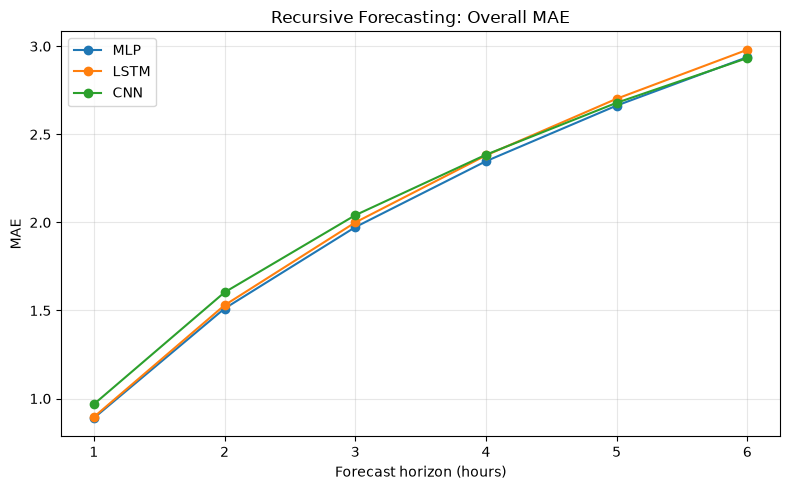

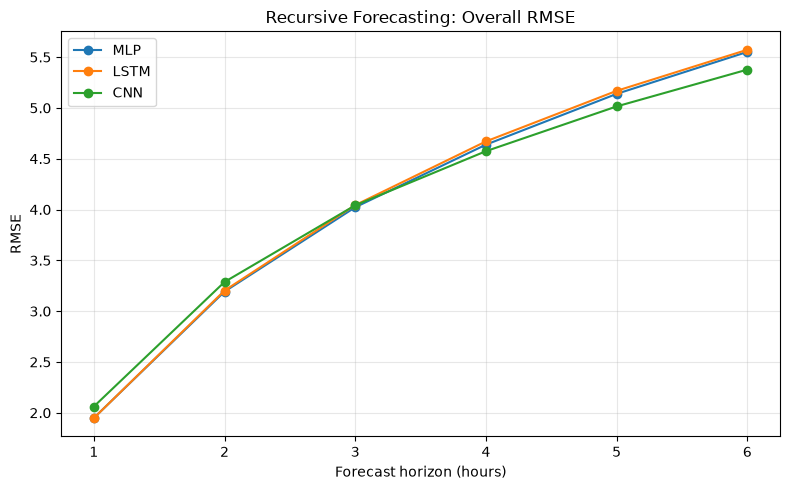

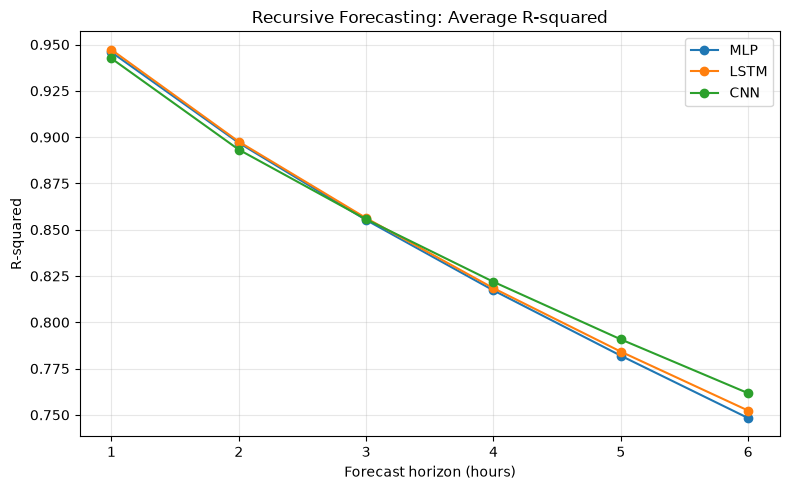

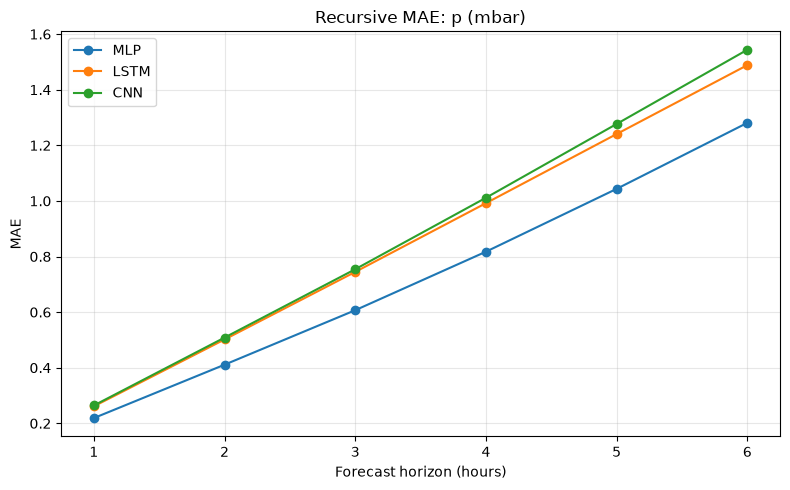

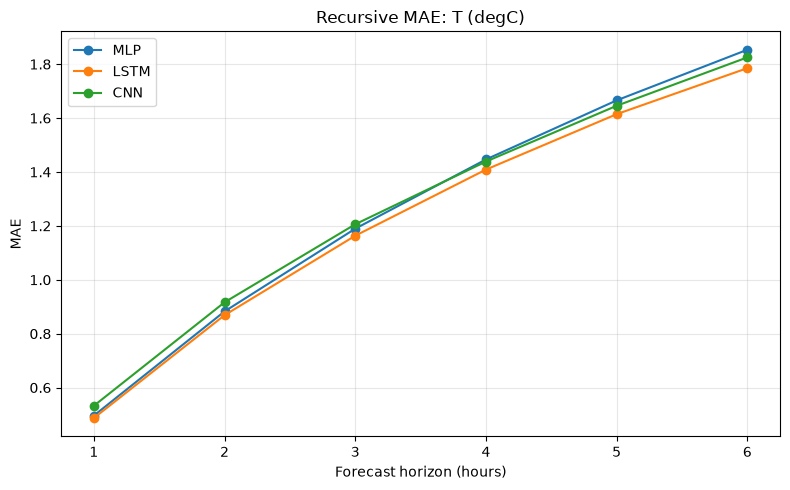

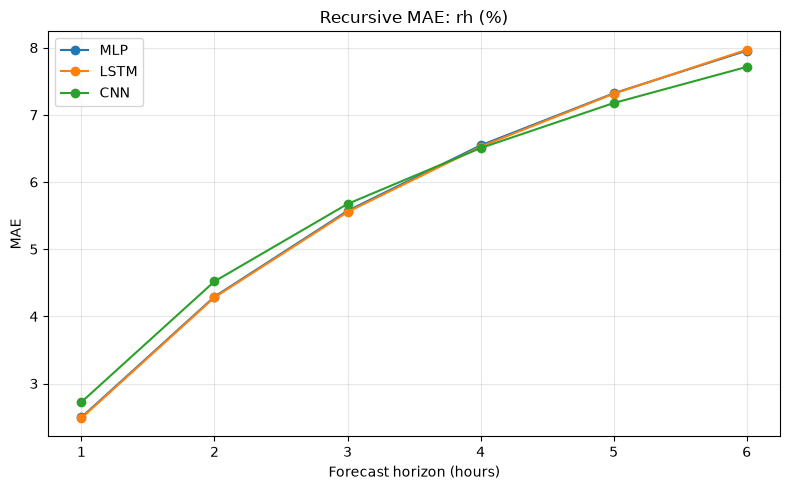

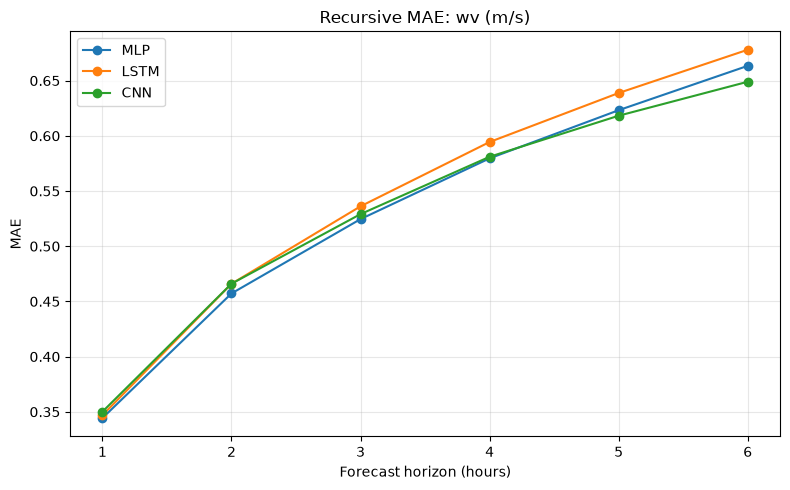

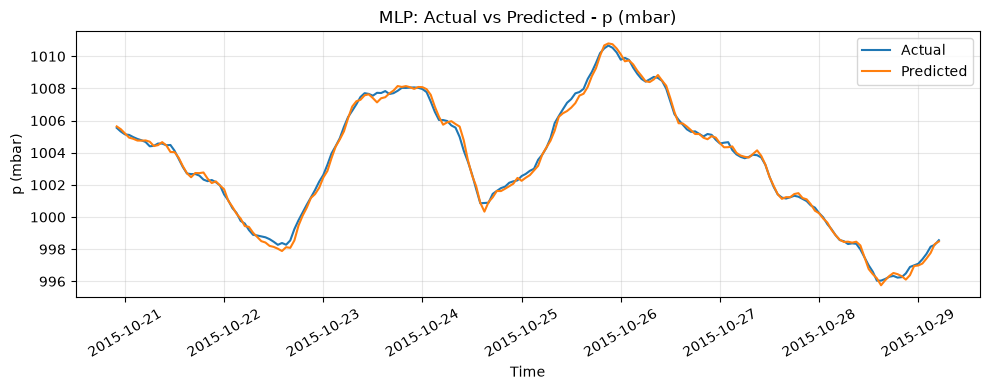

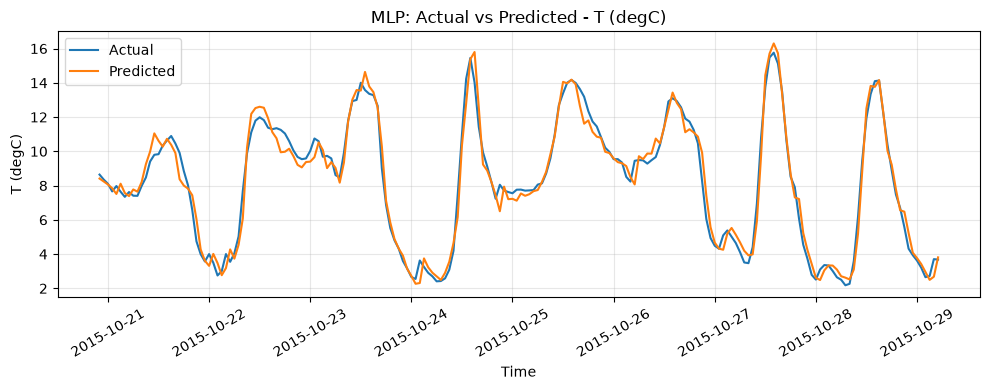

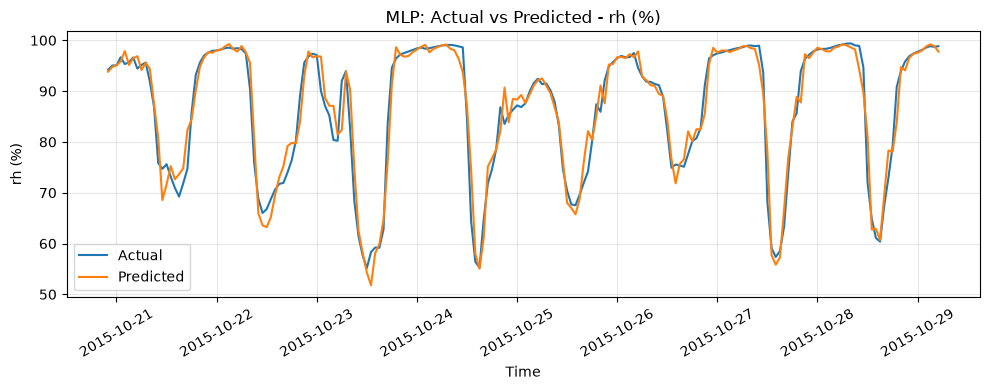

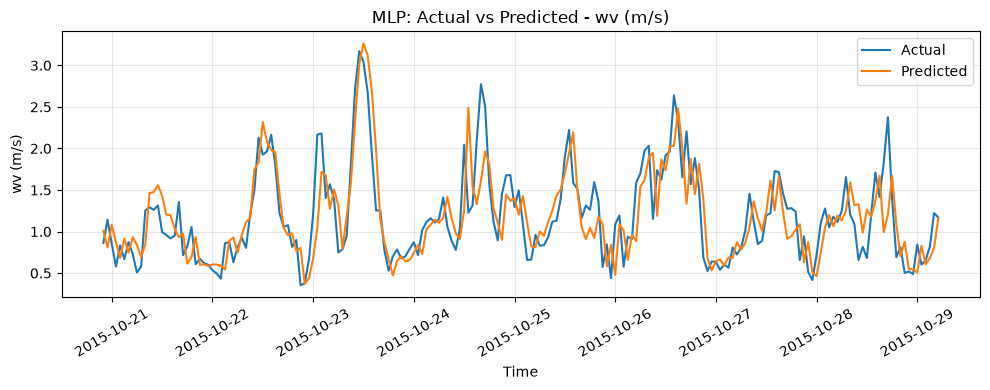

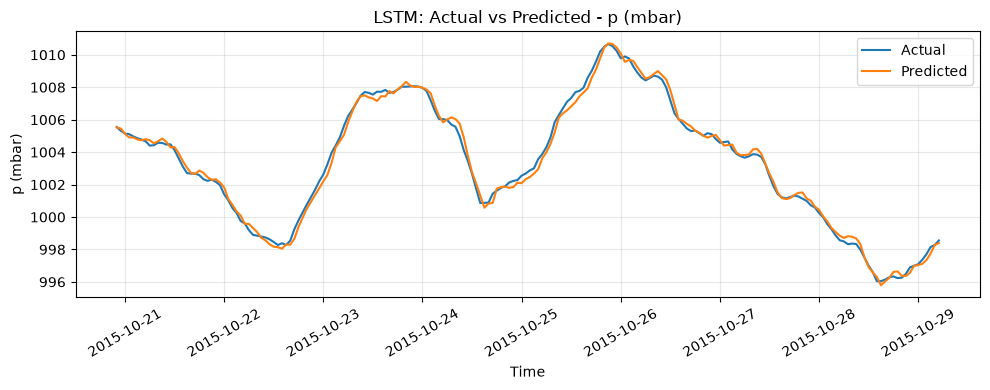

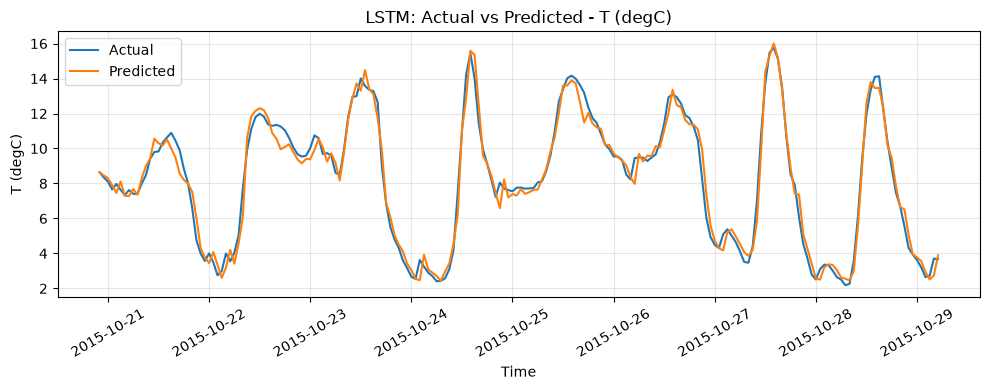

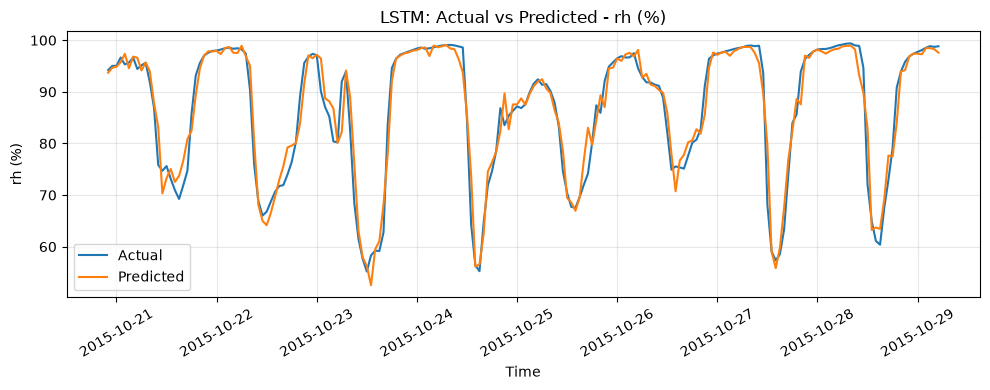

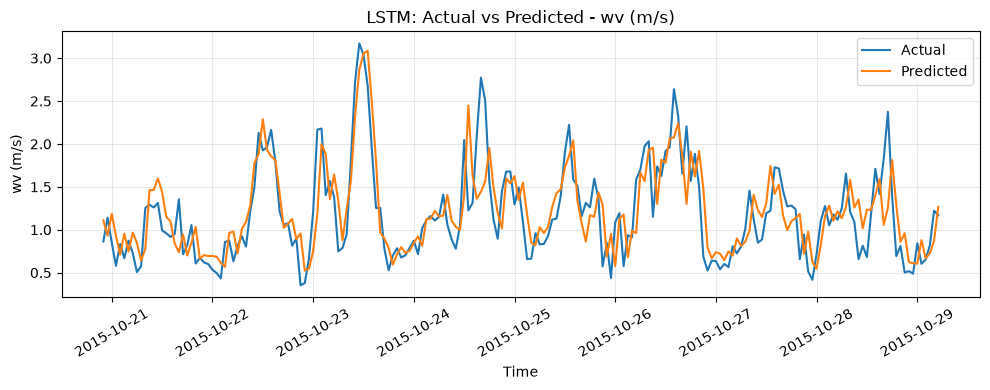

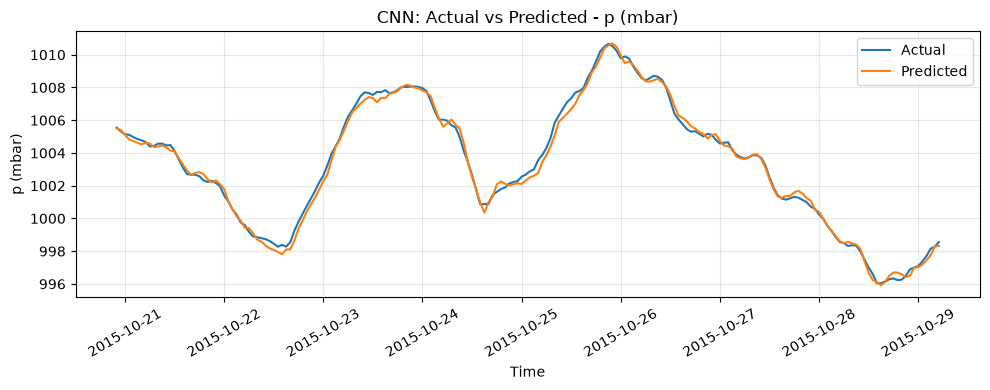

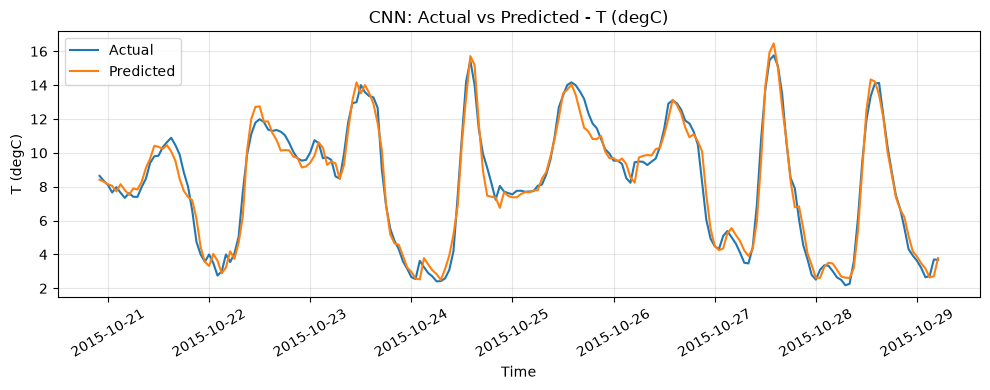

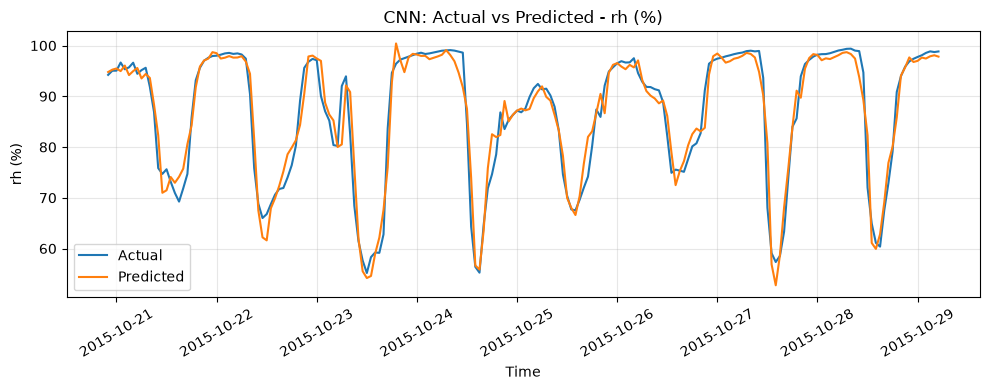

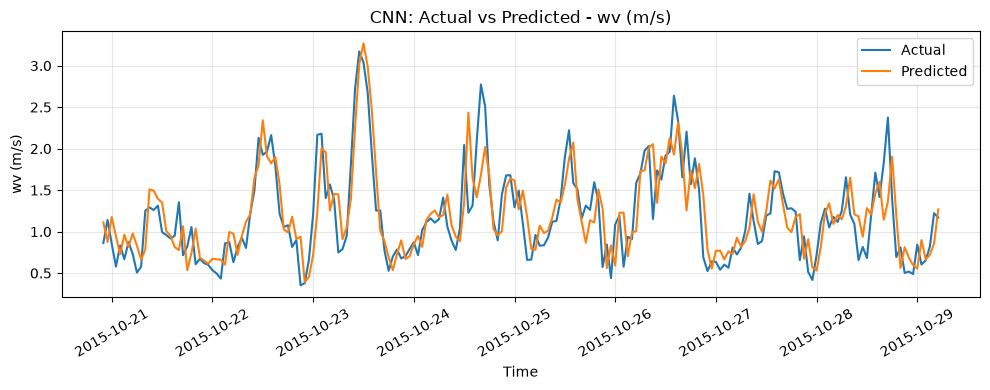

In [9]:
def plot_recursive_metric(metric, title, ylabel, filename):

    plt.figure(figsize=(8, 5))

    for model_name in model_factories:
        sub = recursive_overall_df[
            recursive_overall_df["Model"] == model_name
        ].sort_values("Horizon_hours")

        plt.plot(sub["Horizon_hours"], sub[metric], marker="o", label=model_name)

    plt.xlabel("Forecast horizon (hours)")
    plt.ylabel(ylabel)
    plt.title(title)

    plt.xticks(range(1, HORIZON + 1))
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()

    plt.savefig(FIG_DIR / filename, dpi=300)
    plt.show()
    plt.close()


plot_recursive_metric(
    "Overall_MAE",
    "Recursive Forecasting: Overall MAE",
    "MAE",
    "recursive_overall_mae.png",
)

plot_recursive_metric(
    "Overall_RMSE",
    "Recursive Forecasting: Overall RMSE",
    "RMSE",
    "recursive_overall_rmse.png",
)

plot_recursive_metric(
    "Average_R2",
    "Recursive Forecasting: Average R-squared",
    "R-squared",
    "recursive_overall_r2.png",
)


# Feature-wise recursive MAE plots
for feature in TARGETS:
    sub_all = recursive_feature_df[recursive_feature_df["Feature"] == feature]

    plt.figure(figsize=(8, 5))

    for model_name in model_factories:
        sub = sub_all[sub_all["Model"] == model_name].sort_values("Horizon_hours")

        plt.plot(sub["Horizon_hours"], sub["MAE"], marker="o", label=model_name)

    plt.xlabel("Forecast horizon (hours)")
    plt.ylabel("MAE")
    plt.title(f"Recursive MAE: {feature}")

    plt.xticks(range(1, HORIZON + 1))
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()

    safe_name = re.sub(r"[^A-Za-z0-9]+", "_", feature).strip("_")

    plt.savefig(FIG_DIR / f"recursive_mae_{safe_name}.png", dpi=300)

    plt.show()
    plt.close()


# Actual vs predicted plots
for name in model_factories:
    sub = predictions_df[predictions_df["Model"] == name].head(200)

    for feature in TARGETS:
        plt.figure(figsize=(10, 4))

        plt.plot(sub["Date Time"], sub[f"Actual_{feature}"], label="Actual")

        plt.plot(sub["Date Time"], sub[f"Predicted_{feature}"], label="Predicted")

        plt.xlabel("Time")
        plt.ylabel(feature)
        plt.title(f"{name}: Actual vs Predicted - {feature}")

        plt.xticks(rotation=30)
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.tight_layout()

        safe_name = re.sub(r"[^A-Za-z0-9]+", "_", feature).strip("_")

        plt.savefig(
            FIG_DIR / f"{name.lower()}_actual_vs_predicted_{safe_name}.png", dpi=300
        )

        plt.show()
        plt.close()

In [10]:
print("\n================ FINAL RUN SUMMARY ================")

print("\nPREPROCESSING SUMMARY")
print(json.dumps(preprocess_summary, indent=2))

print("\nSEQUENCE SUMMARY")
print(json.dumps(sequence_summary, indent=2))

print("\nONE-STEP OVERALL RESULTS")
print(overall_df.round(4).to_string(index=False))

print("\nRECURSIVE OVERALL RESULTS")
print(recursive_overall_df.round(4).to_string(index=False))


print("\nFILES GENERATED:")

for path in sorted(OUT_DIR.rglob("*")):
    if path.is_file():
        print(path.relative_to(OUT_DIR), f"({path.stat().st_size:,} bytes)")


# Create ZIP containing all outputs
zip_output = shutil.make_archive(str(OUT_DIR), "zip", root_dir=OUT_DIR)

print("\nOutput ZIP created:", zip_output)

if running_on_colab:
    from google.colab import files

    files.download(zip_output)



================ FINAL RUN SUMMARY ================

PREPROCESSING SUMMARY
{
  "ZIP_files": 16,
  "raw_rows": 419515,
  "invalid_dates_removed": 0,
  "year_mismatches_removed": 1,
  "invalid_wv_replaced": 177,
  "invalid_p": 220,
  "invalid_t": 224,
  "invalid_rh": 553,
  "invalid_wv": 177,
  "exact_duplicates_removed": 27,
  "rows_after_timestamp_aggregation": 419476,
  "repeated_timestamp_rows": 22,
  "hourly_timeline_rows": 70128,
  "missing_hour_rows": 330,
  "complete_hourly_rows": 69798,
  "first_hour": "2009-01-01 00:00:00",
  "last_hour": "2016-12-31 23:00:00"
}

SEQUENCE SUMMARY
{
  "K": 6,
  "train_sequences": 48552,
  "validation_sequences": 10500,
  "test_sequences": 10514,
  "total_sequences": 69566,
  "X_train_shape": [
    48552,
    6,
    8
  ],
  "X_validation_shape": [
    10500,
    6,
    8
  ],
  "X_test_shape": [
    10514,
    6,
    8
  ]
}

ONE-STEP OVERALL RESULTS
Model  Overall_MAE  Overall_RMSE  Average_R2
  MLP       0.8889        1.9484      0.9459
 LSTM